In [ ]:
# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

# STEP 2: Download the dataset

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00352/Online%20Retail.xlsx"
)

df = pd.read_excel(url, engine="openpyxl")

print("Dataset downloaded successfully!")
print("Number of rows and columns:", df.shape)
print("\nFirst 5 rows:")
display(df.head())



Dataset downloaded successfully!
Number of rows and columns: (541909, 8)

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:

# STEP 3: Clean the dataset

print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows without customer IDs
df = df.dropna(subset=["CustomerID"]).copy()

# Convert columns into the correct data types
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["CustomerID"] = df["CustomerID"].astype(int)

# Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Keep only valid positive quantities and prices
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

# Calculate the total revenue for each transaction line
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("\nDataset cleaned successfully!")
print("Remaining rows:", len(df))
display(df.head())


Missing values before cleaning:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Dataset cleaned successfully!
Remaining rows: 397884


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [ ]:

# STEP 4: Create customer features

# Use the last 90 days as the future prediction period
end_date = df["InvoiceDate"].max()
cutoff_date = end_date - pd.Timedelta(days=90)

# Historical transactions: before the cutoff date
history = df[df["InvoiceDate"] < cutoff_date].copy()

# Future transactions: from cutoff date onwards
future = df[df["InvoiceDate"] >= cutoff_date].copy()

# Create one row for each customer using historical data
features = history.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    TotalSpend=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    UniqueProducts=("StockCode", "nunique")
)

# Calculate how recently each customer purchased
features["RecencyDays"] = (
    cutoff_date - features["LastPurchase"]
).dt.days

# Calculate average spending per order
features["AverageOrderValue"] = (
    features["TotalSpend"] / features["Frequency"]
)

# Create the future spending target
target = future.groupby("CustomerID")["Revenue"].sum()
target.name = "Future90DaySpend"

# Customers with no future purchases receive a target value of zero
data = features.join(target, how="left")
data["Future90DaySpend"] = data["Future90DaySpend"].fillna(0)

# Remove the date column; use numerical features for training
data = data.drop(columns=["LastPurchase"])

print("Historical period ends:", cutoff_date)
print("Dataset ends:", end_date)
print("Customer records prepared:", len(data))

display(data.head())


Historical period ends: 2011-09-10 12:50:00
Dataset ends: 2011-12-09 12:50:00
Customer records prepared: 3370


,Frequency,TotalSpend,TotalQuantity,UniqueProducts,RecencyDays,AverageOrderValue,Future90DaySpend
CustomerID,,,,,,,
12346,1,77183.60,74215,1,235,77183.600000,0.00
12347,5,2790.86,1590,82,39,558.172000,1519.14
12348,3,1487.24,2124,22,158,495.746667,310.00
12350,1,334.40,197,17,219,334.400000,0.00
12352,5,1561.81,254,26,171,312.362000,944.23


In [ ]:

# STEP 5: Separate inputs and output

X = data[
    [
        "RecencyDays",
        "Frequency",
        "TotalSpend",
        "TotalQuantity",
        "UniqueProducts",
        "AverageOrderValue"
    ]
]

y = data["Future90DaySpend"]

print("Input features:", X.columns.tolist())
print("Output to predict:", y.name)
print("Number of customers:", len(X))


Input features: ['RecencyDays', 'Frequency', 'TotalSpend', 'TotalQuantity', 'UniqueProducts', 'AverageOrderValue']
Output to predict: Future90DaySpend
Number of customers: 3370


In [ ]:

# STEP 6: Split the data into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))

# Create the Gradient Boosting Regression model
model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Training customers: 2696
Testing customers: 674
Model training completed successfully!


In [ ]:

# STEP 7: Evaluate the trained model

# Predict future spending for test customers
predictions = model.predict(X_test)

# Spending cannot be negative, so set negative predictions to zero
predictions = np.maximum(predictions, 0)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(y_test, predictions)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Mean Absolute Error (MAE): £{mae:.2f}")
print(f"Root Mean Squared Error (RMSE): £{rmse:.2f}")
print(f"R-squared (R²) Score: {r2:.3f}")


MODEL EVALUATION RESULTS
------------------------
Mean Absolute Error (MAE): £1006.51
Root Mean Squared Error (RMSE): £7365.53
R-squared (R²) Score: 0.166


In [ ]:

# STEP 8: Compare with a baseline model

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

print(f"Baseline MAE: £{baseline_mae:.2f}")
print(f"Gradient Boosting MAE: £{mae:.2f}")

if mae < baseline_mae:
    print("Gradient Boosting has lower MAE than the baseline.")
else:
    print("The baseline has lower MAE. Further model improvement is needed.")


Baseline MAE: £1287.70
Gradient Boosting MAE: £1006.51
Gradient Boosting has lower MAE than the baseline.


In [ ]:

# STEP 9: Create a prediction results table

results = pd.DataFrame({
    "CustomerID": X_test.index,
    "ActualFutureSpend": y_test.values,
    "PredictedFutureSpend": predictions
})

results["PredictionError"] = (
    results["ActualFutureSpend"]
    - results["PredictedFutureSpend"]
)

results = results.sort_values(
    by="PredictedFutureSpend",
    ascending=False
)

print("TOP 10 CUSTOMERS BY PREDICTED FUTURE SPENDING")
display(results.head(10).round(2))


TOP 10 CUSTOMERS BY PREDICTED FUTURE SPENDING


,CustomerID,ActualFutureSpend,PredictedFutureSpend,PredictionError
648,14156,18521.29,88528.22,-70006.93
167,14646,101903.40,87003.23,14900.17
135,14911,61847.38,86648.46,-24801.08
399,12346,0.00,31258.01,-31258.01
70,13079,160.60,25410.79,-25250.19
396,16910,1398.28,20180.59,-18782.31
122,13694,19127.98,12792.19,6335.79
287,15311,14612.42,12344.29,2268.13
313,12748,19611.98,11214.78,8397.20
220,12753,4808.48,10869.24,-6060.76


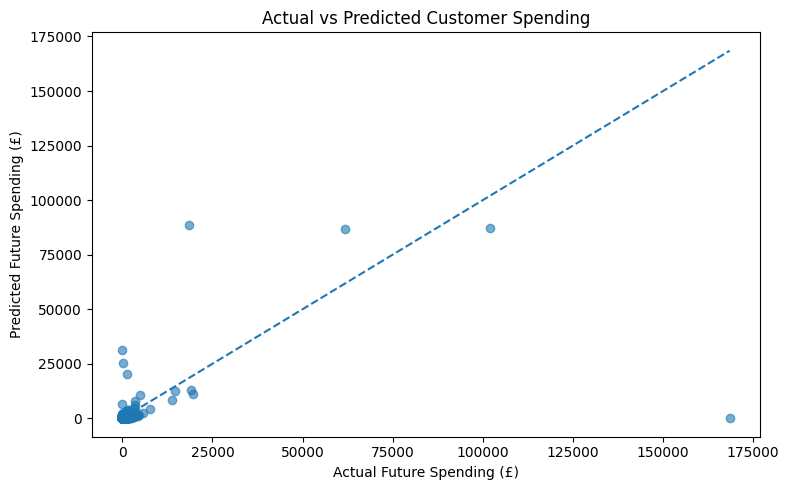

In [ ]:

# STEP 10A: Actual versus predicted spending

plt.figure(figsize=(8, 5))

plt.scatter(y_test, predictions, alpha=0.6)

max_value = max(
    float(y_test.max()),
    float(predictions.max())
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Future Spending (£)")
plt.ylabel("Predicted Future Spending (£)")
plt.title("Actual vs Predicted Customer Spending")
plt.tight_layout()
plt.show()


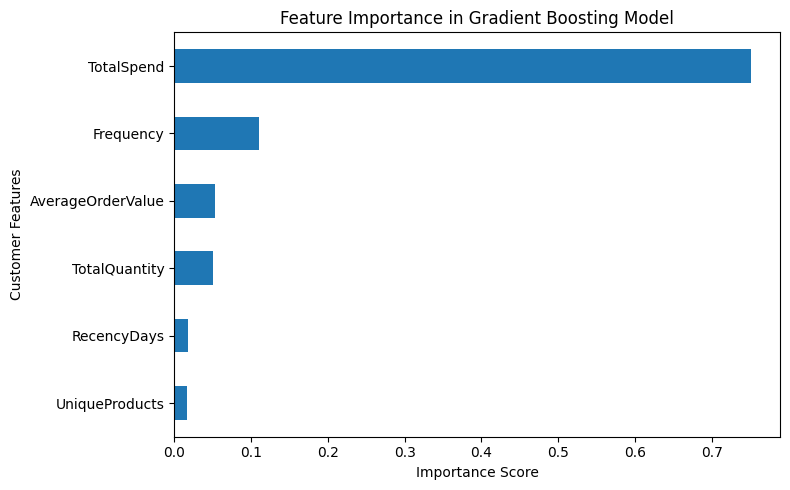

In [ ]:

# STEP 10B: Feature importance

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values()

importance.plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Importance Score")
plt.ylabel("Customer Features")
plt.title("Feature Importance in Gradient Boosting Model")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 11: Save results and download the CSV file

results.to_csv(
    "customer_lifetime_value_predictions.csv",
    index=False
)

print("Prediction results saved successfully!")

from google.colab import files
files.download("customer_lifetime_value_predictions.csv")


Prediction results saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>